# DistilBERT baseline: original AG News test set

Evaluate the best model saved by `05_baseline_training.ipynb` on all 7,600 original test examples. The test set was not used to select the model.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_from_disk
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    precision_recall_fscore_support,
)
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / 'data' / 'processed' / 'ag_news'
MODEL_DIR = PROJECT_ROOT / 'models' / 'distilbert_ag_news_baseline'
RESULTS_DIR = PROJECT_ROOT / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

splits = load_from_disk(str(DATA_DIR))
test = splits['test']
label_names = test.features['label'].names
assert len(test) == 7_600 and len(label_names) == 4
tokenizer = AutoTokenizer.from_pretrained(str(MODEL_DIR), local_files_only=True)
model = AutoModelForSequenceClassification.from_pretrained(str(MODEL_DIR), local_files_only=True)
assert [model.config.id2label[i] for i in range(4)] == label_names
model.eval()
training_config = json.loads((MODEL_DIR / 'training_config.json').read_text(encoding='utf-8'))
print('Best validation loss:', training_config['best_validation_loss'])
print('Original test samples:', len(test))
print('Labels:', label_names)

E:\VGTU\5 semester\Natural Language Processing\lab 4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1471.88it/s]

Best validation loss: 0.2946779131889343
Original test samples: 7600
Labels: ['World', 'Sports', 'Business', 'Sci/Tech']


In [2]:
tokenized_test = test.map(
    lambda batch: tokenizer(batch['text'], truncation=True, max_length=128),
    batched=True,
    remove_columns=test.column_names,
)
loader = DataLoader(
    tokenized_test, batch_size=64,
    collate_fn=DataCollatorWithPadding(tokenizer, return_tensors='pt'),
)
predictions = []
with torch.inference_mode():
    for batch in tqdm(loader, desc='Predicting test set'):
        logits = model(**batch).logits
        predictions.extend(logits.argmax(dim=-1).tolist())

true_labels = np.asarray(test['label'])
predictions = np.asarray(predictions)
assert len(predictions) == len(true_labels) == 7_600
print('Predictions generated:', len(predictions))


Map:   0%|          | 0/7600 [00:00<?, ? examples/s]


Map:  53%|█████▎    | 4000/7600 [00:00<00:00, 15607.80 examples/s]


Map: 100%|██████████| 7600/7600 [00:00<00:00, 22695.65 examples/s]


Map: 100%|██████████| 7600/7600 [00:00<00:00, 19300.51 examples/s]


Predicting test set:   0%|          | 0/119 [00:00<?, ?it/s]

...


Predicting test set:  98%|█████████▊| 117/119 [03:07<00:03,  1.68s/it]


Predicting test set:  99%|█████████▉| 118/119 [03:08<00:01,  1.71s/it]


Predicting test set: 100%|██████████| 119/119 [03:09<00:00,  1.46s/it]


Predicting test set: 100%|██████████| 119/119 [03:09<00:00,  1.59s/it]

Predictions generated: 7600


In [3]:
labels = list(range(len(label_names)))
precision, recall, f1, support = precision_recall_fscore_support(
    true_labels, predictions, labels=labels, zero_division=0
)
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    true_labels, predictions, labels=labels, average='macro', zero_division=0
)
cm = confusion_matrix(true_labels, predictions, labels=labels)
metrics = {
    'model': str(MODEL_DIR),
    'dataset': 'original AG News test split',
    'test_samples': len(test),
    'accuracy': float(accuracy_score(true_labels, predictions)),
    'macro_precision': float(macro_precision),
    'macro_recall': float(macro_recall),
    'macro_f1': float(macro_f1),
    'per_class': {
        name: {
            'precision': float(precision[i]), 'recall': float(recall[i]),
            'f1': float(f1[i]), 'support': int(support[i]),
        } for i, name in enumerate(label_names)
    },
    'confusion_matrix': cm.tolist(),
    'confusion_matrix_labels': label_names,
}
print(pd.Series({key: value for key, value in metrics.items() if key in (
    'accuracy', 'macro_precision', 'macro_recall', 'macro_f1')}))
display(pd.DataFrame(metrics['per_class']).T.round(4))

accuracy           0.907763
macro_precision    0.908052
macro_recall       0.907763
macro_f1           0.907682
dtype: float64


,precision,recall,f1,support
World,0.9259,0.8947,0.9101,1900.0
Sports,0.9574,0.9811,0.9691,1900.0
Business,0.8524,0.8847,0.8683,1900.0
Sci/Tech,0.8965,0.8705,0.8833,1900.0


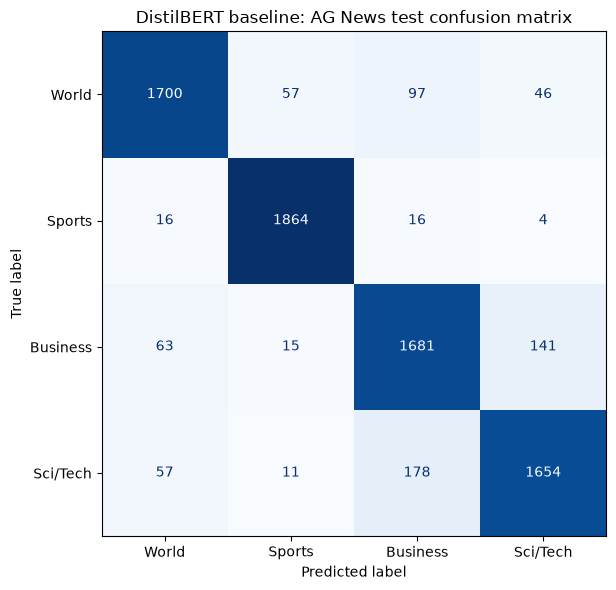

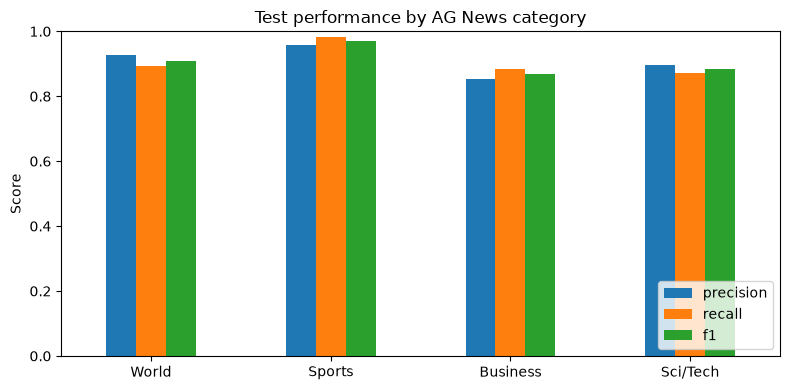

In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names).plot(
    ax=ax, cmap='Blues', values_format='d', colorbar=False
)
ax.set_title('DistilBERT baseline: AG News test confusion matrix')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'baseline_confusion_matrix.png', dpi=160)
plt.show()

class_frame = pd.DataFrame(metrics['per_class']).T
ax = class_frame[['precision', 'recall', 'f1']].plot.bar(
    figsize=(8, 4), rot=0, ylim=(0, 1), title='Test performance by AG News category'
)
ax.set_ylabel('Score')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'baseline_per_class_metrics.png', dpi=160)
plt.show()

In [5]:
incorrect_indices = np.flatnonzero(true_labels != predictions)
assert len(incorrect_indices) >= 5
incorrect_examples = [
    {
        'test_index': int(index),
        'true_label': label_names[int(true_labels[index])],
        'predicted_label': label_names[int(predictions[index])],
        'text': test[int(index)]['text'],
    }
    for index in incorrect_indices[:10]
]
metrics['incorrect_count'] = len(incorrect_indices)
metrics['incorrect_examples'] = incorrect_examples
display(pd.DataFrame(incorrect_examples))
print('Incorrect predictions:', len(incorrect_indices))
print('Lowest category F1:', min(metrics['per_class'], key=lambda name: metrics['per_class'][name]['f1']))
metrics_path = RESULTS_DIR / 'baseline_metrics.json'
metrics_path.write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved:', metrics_path)

,test_index,true_label,predicted_label,text
0,9,Sci/Tech,Business,"Card fraud unit nets 36,000 cards In its first..."
1,23,Sci/Tech,Business,Some People Not Eligible to Get in on Google I...
2,24,Sci/Tech,Business,Rivals Try to Turn Tables on Charles Schwab By...
3,47,Sci/Tech,Business,Dell Exits Low-End China Consumer PC Market H...
4,79,World,Sports,Live: Olympics day four Richard Faulds and Ste...
5,83,Business,Sci/Tech,Intel to delay product aimed for high-definiti...
6,88,World,Sports,"U.S. Misses Cut in Olympic 100 Free ATHENS, Gr..."
7,106,World,Business,Stocks Climb on Drop in Consumer Prices NEW YO...
8,110,Business,Sci/Tech,Yahoo! Ups Ante for Small Businesses Web giant...
9,111,Sci/Tech,Business,IBM Buys Two Danish Services Firms IBM said Tu...


Incorrect predictions: 701
Lowest category F1: Business
Saved: E:\VGTU\5 semester\Natural Language Processing\lab 4\results\baseline_metrics.json


## Category analysis

Sports performs best (F1 = 0.969), while Business performs worst (F1 = 0.868). World and Sci/Tech score 0.910 and 0.883 F1, respectively. The largest confusion is between Sci/Tech and Business: 178 Sci/Tech articles were predicted as Business, and 141 Business articles were predicted as Sci/Tech. Overall, 701 of 7,600 test articles were misclassified. The ten examples above show cases for qualitative review.